In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('CIC-BCCC-NRC-TabularIoTAttacks-2024-balanced_dataset.csv')

In [3]:
df.head()

,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_type,Attack
0,6,4581649,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.654786,2290824.5,2.905022e+06,4344985.0,236664.0,4344985.0,4344985.0,0.0,4344985.0,4344985.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.436524,0.218262,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
1,6,300972,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.645136,300972.0,0.000000e+00,300972.0,300972.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,20,20,3.322568,3.322568,0.0,0.0,0.0,0.0,0.0,0,0,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
2,6,7462882,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.401989,3731441.0,4.894292e+06,7192228.0,270654.0,7192228.0,7192228.0,0.0,7192228.0,7192228.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.267993,0.133996,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,7192228.0,0.0,7192228.0,7192228.0,1,DDoS,ACK Flood
3,6,304278,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.572937,304278.0,0.000000e+00,304278.0,304278.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,20,20,3.286468,3.286468,0.0,0.0,0.0,0.0,0.0,0,0,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
4,6,9177775,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.326877,4588887.5,6.205263e+06,8976671.0,201104.0,8976671.0,8976671.0,0.0,8976671.0,8976671.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.217918,0.108959,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,8976671.0,0.0,8976671.0,8976671.0,1,DDoS,ACK Flood


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().any().any()

False

In [6]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [7]:
df.shape

(1076588, 80)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1076588 entries, 0 to 1076587
Data columns (total 80 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   Protocol                    1076588 non-null  int64  
 1   Flow Duration               1076588 non-null  int64  
 2   Total Fwd Packet            1076588 non-null  int64  
 3   Total Bwd packets           1076588 non-null  int64  
 4   Total Length of Fwd Packet  1076588 non-null  float64
 5   Total Length of Bwd Packet  1076588 non-null  float64
 6   Fwd Packet Length Max       1076588 non-null  float64
 7   Fwd Packet Length Min       1076588 non-null  float64
 8   Fwd Packet Length Mean      1076588 non-null  float64
 9   Fwd Packet Length Std       1076588 non-null  float64
 10  Bwd Packet Length Max       1076588 non-null  float64
 11  Bwd Packet Length Min       1076588 non-null  float64
 12  Bwd Packet Length Mean      1076588 non-null  float64
 1

In [3]:
df = df.drop(['Attack', 'Label'], axis=1)

In [10]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [4]:
df['Attack_type'].unique()

array(['DDoS', 'Malware', 'Benign', 'Brute Force', 'DoS', 'MITM', 'MQTT',
       'Botnet (Mirai)', 'Recon', 'Web Attack'], dtype=object)

In [5]:
df = df.drop(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Bytes/Bulk Avg', 
              'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg', 'URG Flag Count', 'CWR Flag Count', 'Fwd URG Flags'], axis=1)

<h2>Outliers</h2>

In [6]:
df2 = df.copy()

In [7]:
df2['Attack_type'].unique()

array(['DDoS', 'Malware', 'Benign', 'Brute Force', 'DoS', 'MITM', 'MQTT',
       'Botnet (Mirai)', 'Recon', 'Web Attack'], dtype=object)

In [8]:
attack_mapping = {
    'Benign': 0,
    'DDoS': 1,
    'Malware': 2,
    'Brute Force': 3,
    'DoS': 4,
    'MITM': 5,
    'MQTT': 6,
    'Botnet (Mirai)': 7,
    'Recon': 8,
    'Web Attack': 9 
}

df2['Attack_type'] = df2['Attack_type'].apply(lambda x: attack_mapping[x])

In [9]:
df2['Attack_type'].unique()

array([1, 2, 0, 3, 4, 5, 6, 7, 8, 9], dtype=int64)

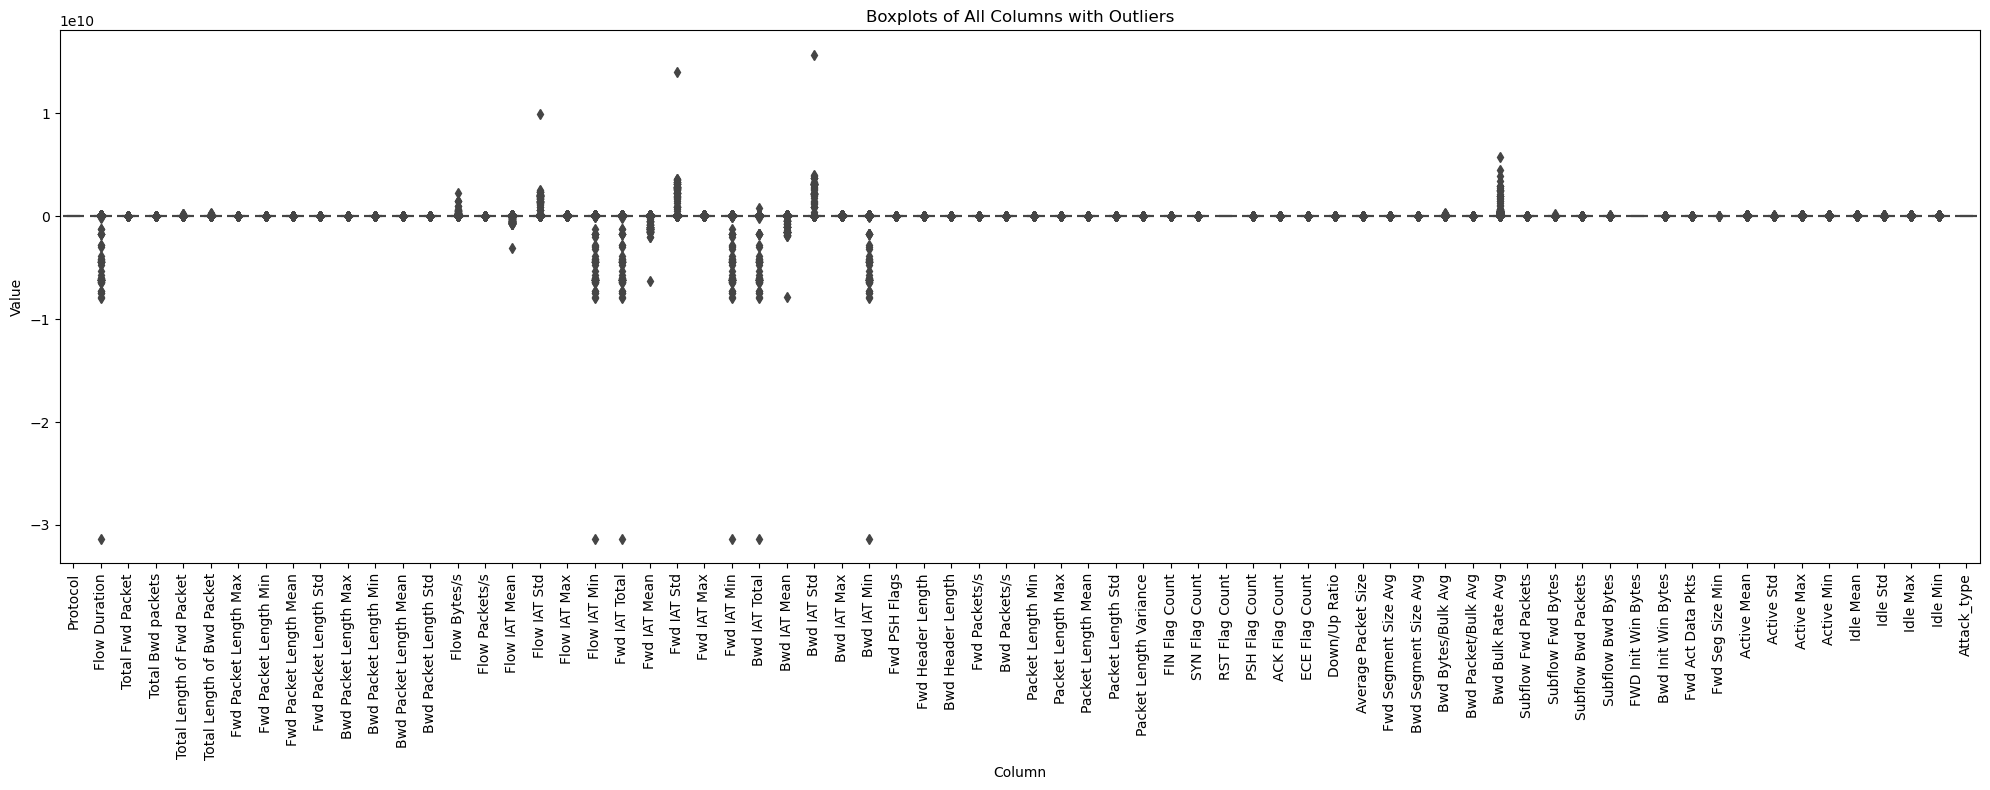

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

In [11]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [12]:
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 187276,
 'Total Fwd Packet': 101474,
 'Total Bwd packets': 82392,
 'Total Length of Fwd Packet': 218708,
 'Total Length of Bwd Packet': 235451,
 'Fwd Packet Length Max': 211078,
 'Fwd Packet Length Min': 69940,
 'Fwd Packet Length Mean': 215848,
 'Fwd Packet Length Std': 186950,
 'Bwd Packet Length Max': 234713,
 'Bwd Packet Length Min': 40220,
 'Bwd Packet Length Mean': 236526,
 'Bwd Packet Length Std': 201638,
 'Flow Bytes/s': 247746,
 'Flow Packets/s': 141990,
 'Flow IAT Mean': 180270,
 'Flow IAT Std': 212439,
 'Flow IAT Max': 160066,
 'Flow IAT Min': 226362,
 'Fwd IAT Total': 195049,
 'Fwd IAT Mean': 178881,
 'Fwd IAT Std': 225292,
 'Fwd IAT Max': 162928,
 'Fwd IAT Min': 211025,
 'Bwd IAT Total': 236209,
 'Bwd IAT Mean': 221740,
 'Bwd IAT Std': 241932,
 'Bwd IAT Max': 222593,
 'Bwd IAT Min': 239503,
 'Fwd PSH Flags': 95361,
 'Fwd Header Length': 91161,
 'Bwd Header Length': 71362,
 'Fwd Packets/s': 134854,
 'Bwd Packets/s': 176220,
 'Packet Length 

In [13]:
outliers_per_column.pop("Attack_type")
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 187276,
 'Total Fwd Packet': 101474,
 'Total Bwd packets': 82392,
 'Total Length of Fwd Packet': 218708,
 'Total Length of Bwd Packet': 235451,
 'Fwd Packet Length Max': 211078,
 'Fwd Packet Length Min': 69940,
 'Fwd Packet Length Mean': 215848,
 'Fwd Packet Length Std': 186950,
 'Bwd Packet Length Max': 234713,
 'Bwd Packet Length Min': 40220,
 'Bwd Packet Length Mean': 236526,
 'Bwd Packet Length Std': 201638,
 'Flow Bytes/s': 247746,
 'Flow Packets/s': 141990,
 'Flow IAT Mean': 180270,
 'Flow IAT Std': 212439,
 'Flow IAT Max': 160066,
 'Flow IAT Min': 226362,
 'Fwd IAT Total': 195049,
 'Fwd IAT Mean': 178881,
 'Fwd IAT Std': 225292,
 'Fwd IAT Max': 162928,
 'Fwd IAT Min': 211025,
 'Bwd IAT Total': 236209,
 'Bwd IAT Mean': 221740,
 'Bwd IAT Std': 241932,
 'Bwd IAT Max': 222593,
 'Bwd IAT Min': 239503,
 'Fwd PSH Flags': 95361,
 'Fwd Header Length': 91161,
 'Bwd Header Length': 71362,
 'Fwd Packets/s': 134854,
 'Bwd Packets/s': 176220,
 'Packet Length 

In [14]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

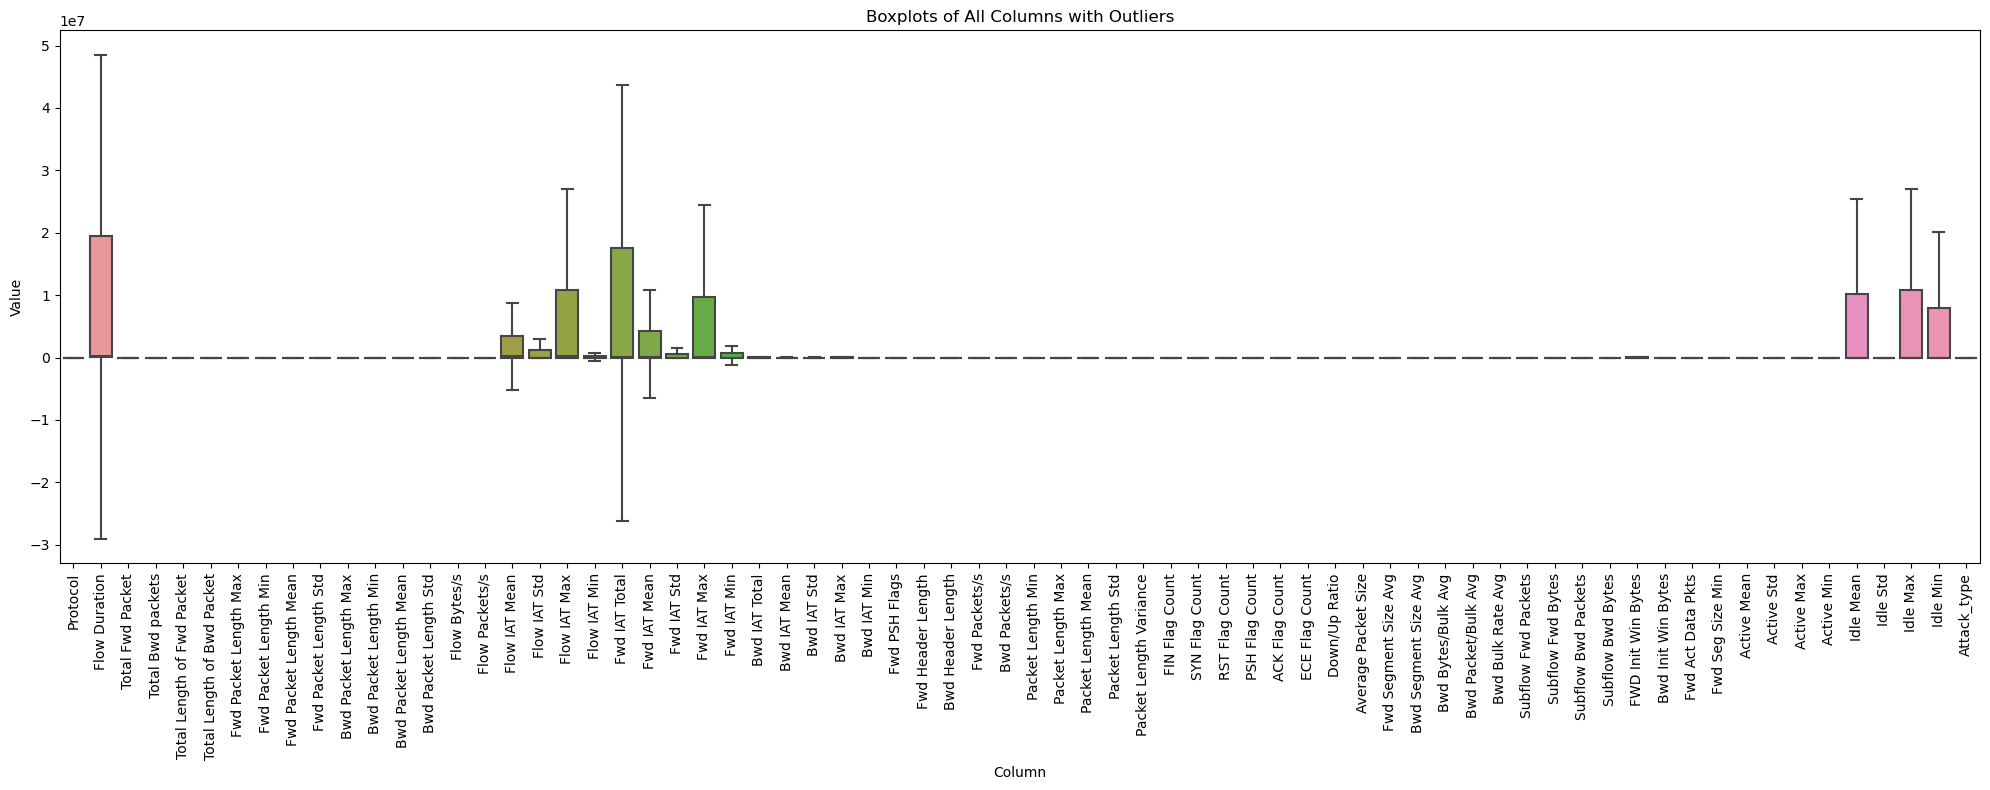

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

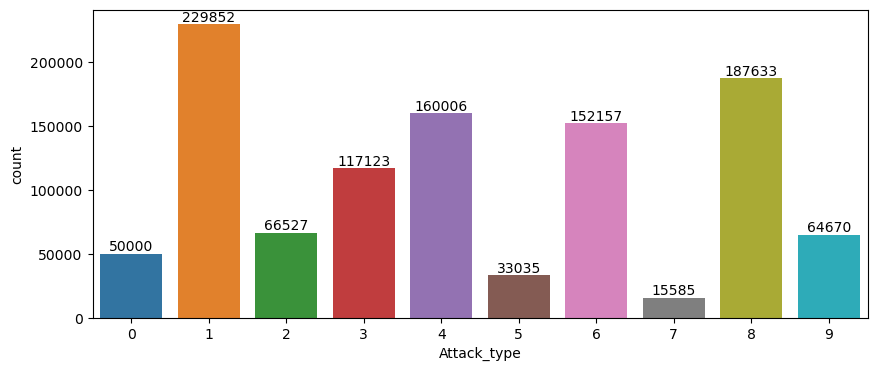

In [23]:
plt.figure(figsize=(10,4))
ax = sns.countplot(x='Attack_type',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [16]:
df2.shape

(1076588, 70)

In [17]:
df2.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
      

In [18]:
columns = ['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
       'Bwd Bytes/Bulk Avg', 'Bwd Packet/Bulk Avg', 'Bwd Bulk Rate Avg', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Act Data Pkts', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']

In [29]:
!pip install --upgrade scikit-learn
!pip install --upgrade imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB 217.9 kB/s eta 0:00:41
   ---------------------------------------- 0.1/8.9 MB 656.4 kB/s eta 0:00:14
   - -------------------------------------- 0.2/8.9 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.9 MB 2.0 MB/s eta 0:00:05
   --- ------------------------------------ 0.7/8.9 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/8.9 MB 4.6 MB/s eta 0:00:02
   -------- ------------------------------- 1.8/8.9 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/8.9 MB 5.2 MB/s eta 0:00:02
   -------------- --

  You can safely remove it manually.


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/240.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/240.0 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/240.0 kB 262.6 kB/s eta 0:00:01
   --------- ----------------------------- 61.4/240.0 kB 465.5 kB/s eta 0:00:01
   ---------------------------------- ----- 204.8/240.0 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 240.0/240.0 kB 1.2 MB/s eta 0:00:00


In [19]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Attack_type'])
y = df2['Attack_type']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Attack_type
1    183881
8    150106
4    128005
6    121726
3     93698
2     53222
9     51736
0     40000
5     26428
7     12468
Name: count, dtype: int64
Attack_type
1    183881
4    183881
9    183881
5    183881
6    183881
2    183881
3    183881
8    183881
0    183881
7    183881
Name: count, dtype: int64


<h2>ML Models</h2>

In [31]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [33]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [34]:
pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



🔹 Training Logistic Regression...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Performance:
  Accuracy:  0.8427
  Precision: 0.8452
  Recall:    0.8427
  F1-score:  0.8415

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.83      0.88     10000
           1       0.93      0.90      0.91     45971
           2       0.79      0.68      0.73     13305
           3       0.78      0.82      0.80     23425
           4       0.92      0.87      0.89     32001
           5       0.61      0.47      0.53      6607
           6       0.92      0.93      0.93     30431
           7       0.67      0.41      0.51      3117
           8       0.74      0.87      0.80     37527
           9       0.78      0.81      0.79     12934

    accuracy                           0.84    215318
   macro avg       0.81      0.76      0.78    215318
weighted avg       0.85      0.84      0.84    215318



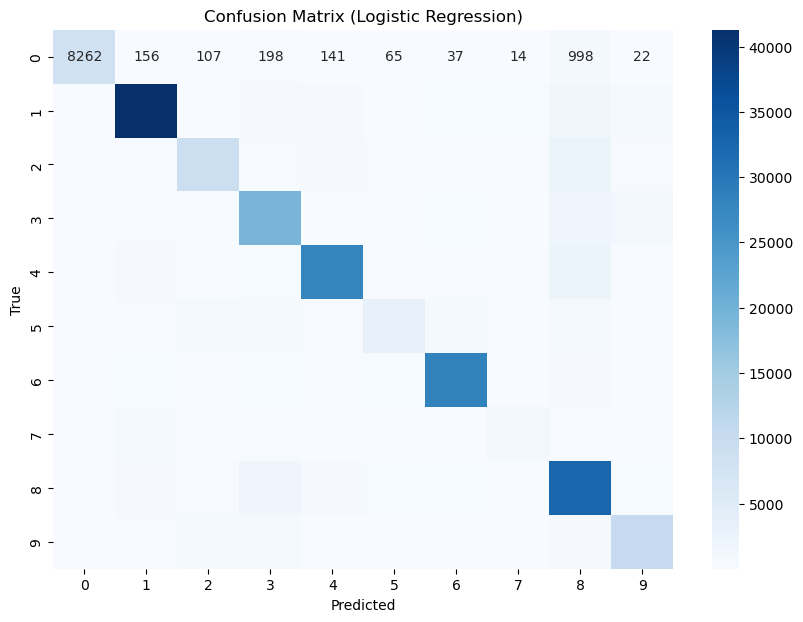


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.9489
  Precision: 0.9487
  Recall:    0.9489
  F1-score:  0.9486

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.88      0.91     10000
           1       0.98      0.99      0.98     45971
           2       0.94      0.97      0.95     13305
           3       0.94      0.93      0.93     23425
           4       0.97      0.96      0.97     32001
           5       0.77      0.70      0.73      6607
           6       0.98      0.98      0.98     30431
           7       0.90      0.88      0.89      3117
           8       0.91      0.95      0.93     37527
           9       0.95      0.95      0.95     12934

    accuracy                           0.95    215318
   macro avg       0.93      0.92      0.92    215318
weighted avg       0.95      0.95      0.95    215318



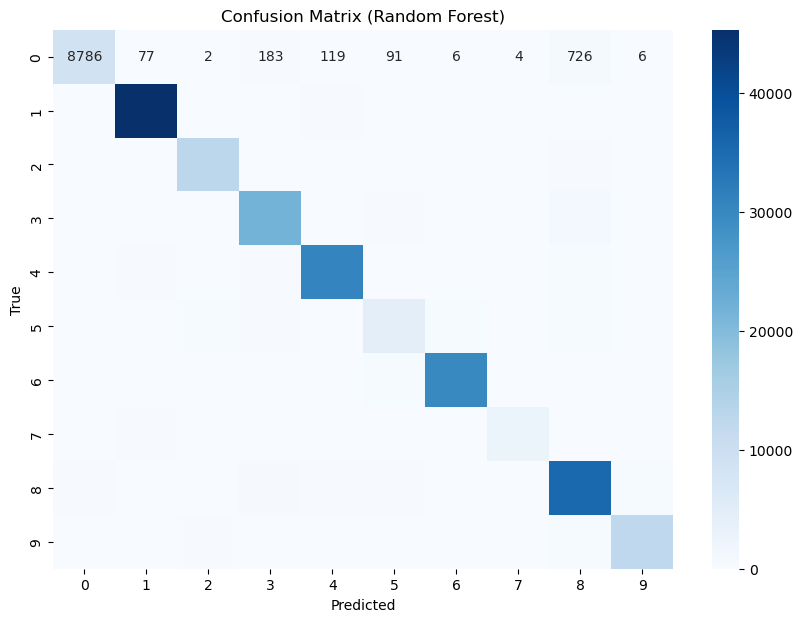


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [16:47:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.9530
  Precision: 0.9538
  Recall:    0.9530
  F1-score:  0.9526

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.87      0.91     10000
           1       0.98      0.99      0.98     45971
           2       0.95      0.97      0.96     13305
           3       0.96      0.92      0.94     23425
           4       0.98      0.95      0.97     32001
           5       0.83      0.69      0.75      6607
           6       0.98      0.99      0.99     30431
           7       0.89      0.89      0.89      3117
           8       0.88      0.98      0.93     37527
           9       0.98      0.94      0.96     12934

    accuracy                           0.95    215318
   macro avg       0.94      0.92      0.93    215318
weighted avg       0.95      0.95      0.95    215318



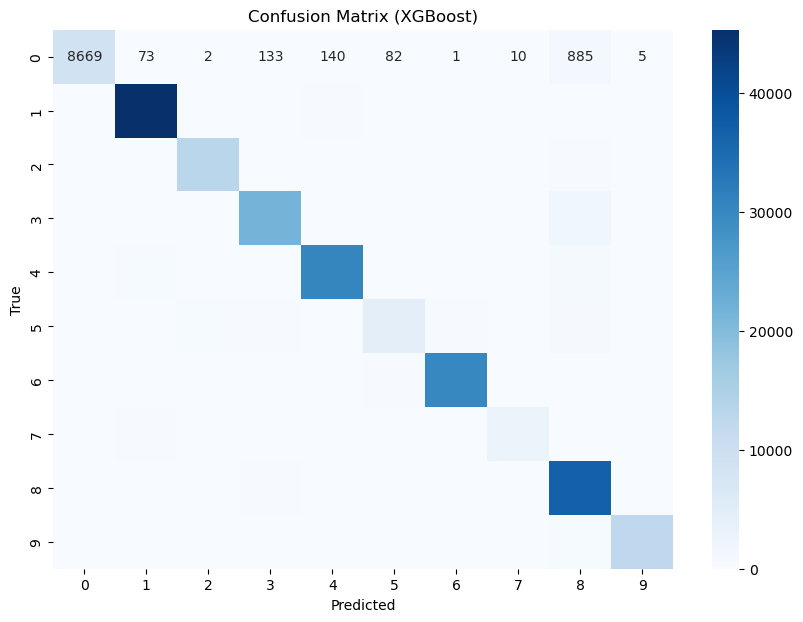


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.9430
  Precision: 0.9425
  Recall:    0.9430
  F1-score:  0.9425

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.87      0.90     10000
           1       0.97      0.98      0.98     45971
           2       0.94      0.97      0.96     13305
           3       0.92      0.92      0.92     23425
           4       0.97      0.95      0.96     32001
           5       0.78      0.67      0.72      6607
           6       0.98      0.98      0.98     30431
           7       0.85      0.79      0.82      3117
           8       0.90      0.95      0.92     37527
           9       0.96      0.93      0.94     12934

    accuracy                           0.94    215318
   macro avg       0.92      0.90      0.91    215318
weighted avg       0.94      0.94      0.94    215318



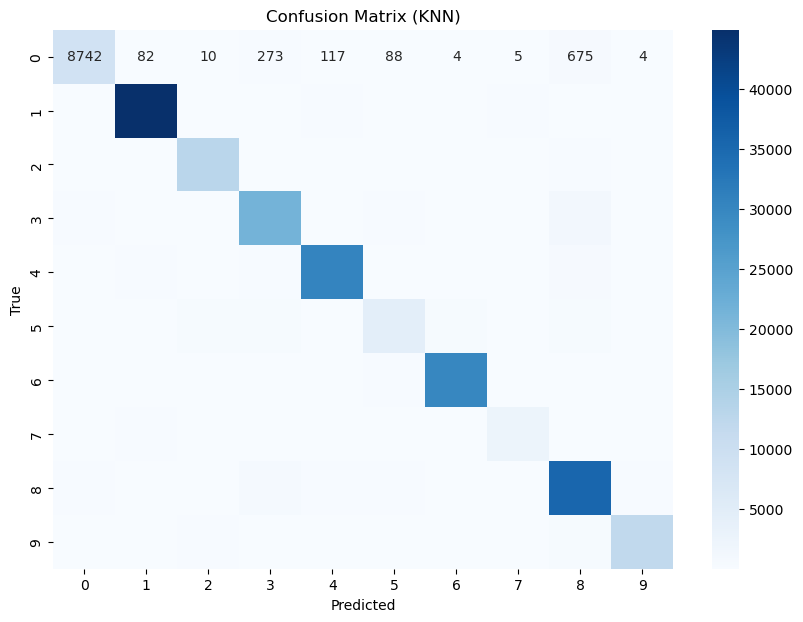


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.5408
  Precision: 0.5592
  Recall:    0.5408
  F1-score:  0.5307

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.63      0.58     10000
           1       0.87      0.65      0.74     45971
           2       0.00      0.00      0.00     13305
           3       0.44      0.32      0.37     23425
           4       0.58      0.62      0.60     32001
           5       0.03      0.03      0.03      6607
           6       0.81      0.51      0.62     30431
           7       0.02      0.01      0.02      3117
           8       0.47      0.75      0.58     37527
           9       0.32      0.71      0.44     12934

    accuracy                           0.54    215318
   macro avg       0.41      0.42      0.40    215318
weighted avg       0.56      0.54      0.53    215318



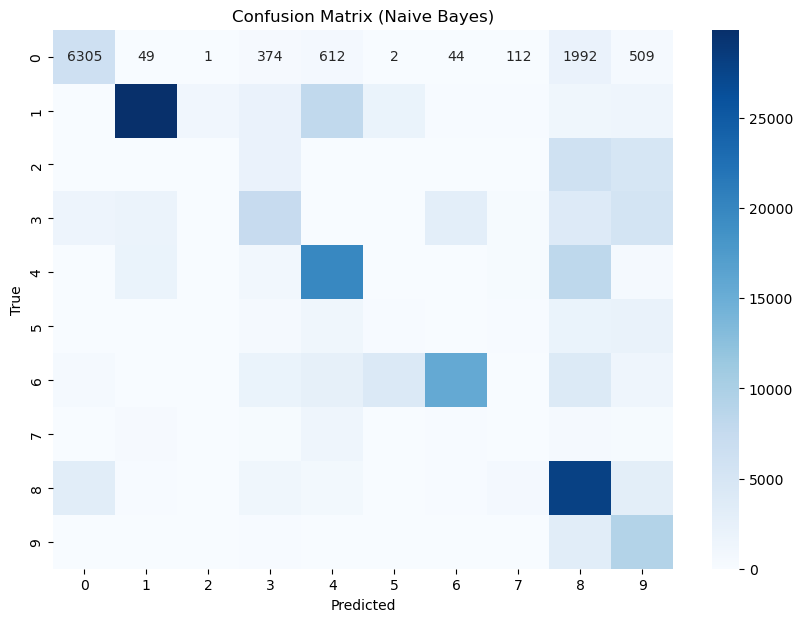


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.9044
  Precision: 0.9055
  Recall:    0.9044
  F1-score:  0.9040

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.86      0.89     10000
           1       0.99      0.94      0.97     45971
           2       0.81      0.93      0.87     13305
           3       0.81      0.89      0.85     23425
           4       0.94      0.94      0.94     32001
           5       0.63      0.51      0.57      6607
           6       0.97      0.96      0.97     30431
           7       0.84      0.66      0.74      3117
           8       0.87      0.90      0.88     37527
           9       0.89      0.86      0.87     12934

    accuracy                           0.90    215318
   macro avg       0.87      0.84      0.85    215318
weighted avg       0.91      0.90      0.90    215318



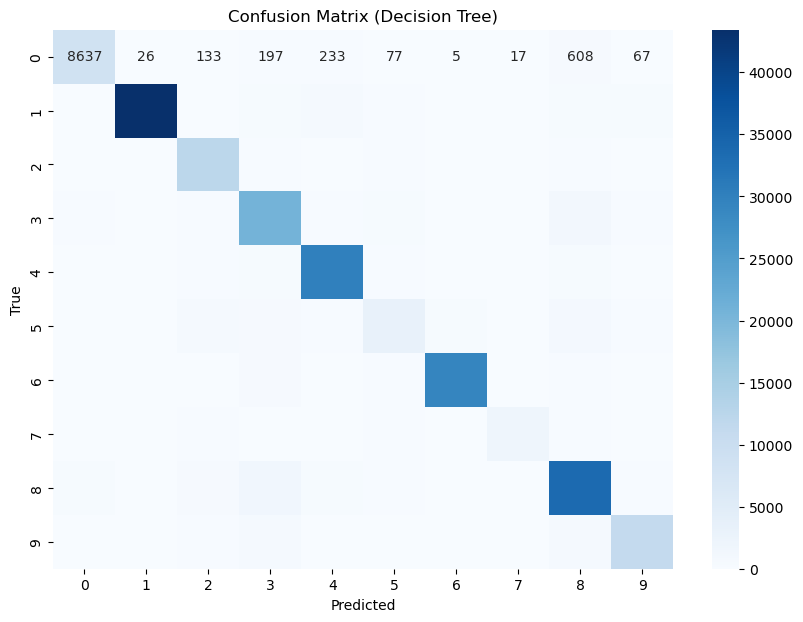


🔹 Training Gradient Boosting...
Gradient Boosting Performance:
  Accuracy:  0.9402
  Precision: 0.9406
  Recall:    0.9402
  F1-score:  0.9395

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.86      0.91     10000
           1       0.97      0.98      0.97     45971
           2       0.94      0.96      0.95     13305
           3       0.94      0.90      0.92     23425
           4       0.97      0.94      0.96     32001
           5       0.77      0.62      0.68      6607
           6       0.98      0.99      0.98     30431
           7       0.87      0.83      0.85      3117
           8       0.87      0.96      0.91     37527
           9       0.96      0.94      0.95     12934

    accuracy                           0.94    215318
   macro avg       0.92      0.90      0.91    215318
weighted avg       0.94      0.94      0.94    215318



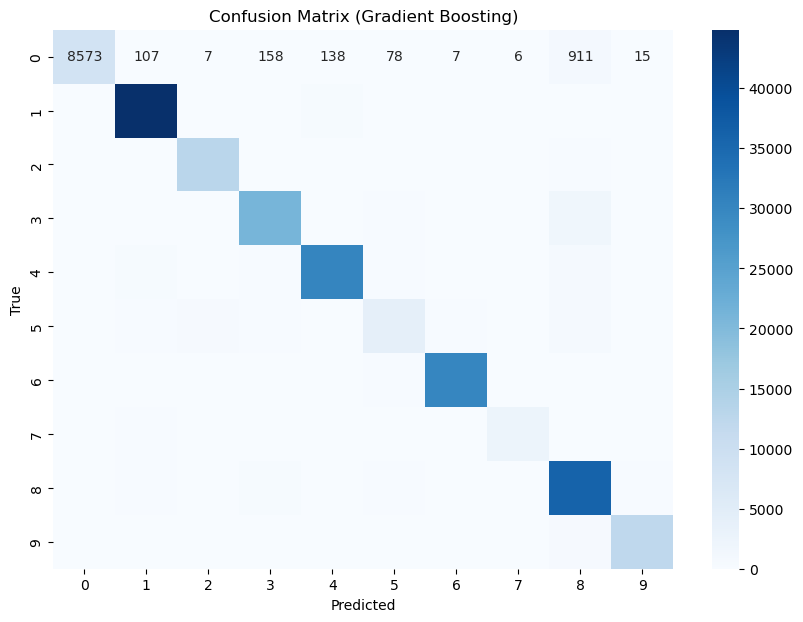


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.4636
  Precision: 0.3651
  Recall:    0.4636
  F1-score:  0.3806

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00     10000
           1       0.60      0.81      0.69     45971
           2       0.00      0.00      0.00     13305
           3       0.37      0.67      0.47     23425
           4       0.40      0.07      0.12     32001
           5       0.00      0.00      0.00      6607
           6       0.50      0.60      0.54     30431
           7       0.00      0.00      0.00      3117
           8       0.39      0.70      0.50     37527
           9       0.00      0.00      0.00     12934

    accuracy                           0.46    215318
   macro avg       0.23      0.29      0.23    215318
weighted avg       0.37      0.46      0.38    215318



C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

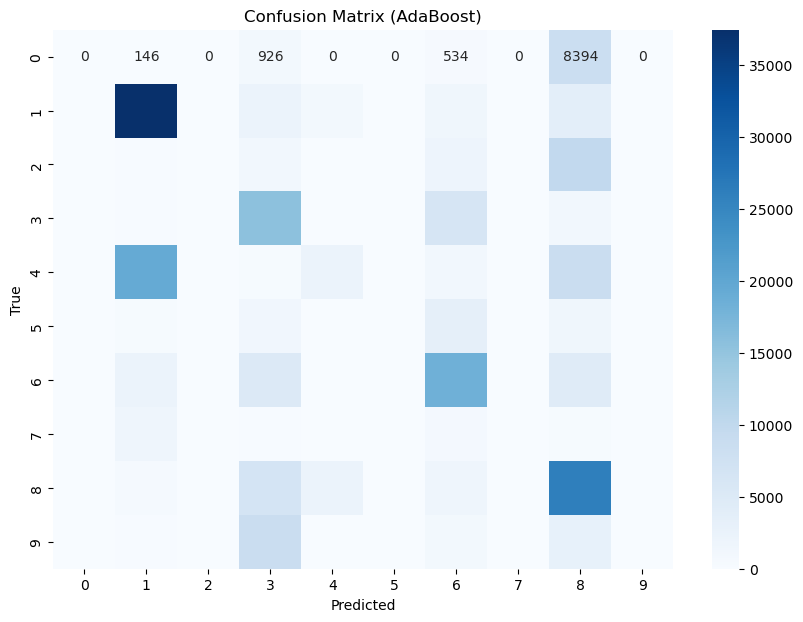


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.9464
  Precision: 0.9461
  Recall:    0.9464
  F1-score:  0.9461

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.88      0.91     10000
           1       0.98      0.98      0.98     45971
           2       0.94      0.96      0.95     13305
           3       0.94      0.92      0.93     23425
           4       0.97      0.96      0.96     32001
           5       0.75      0.70      0.72      6607
           6       0.98      0.98      0.98     30431
           7       0.88      0.87      0.87      3117
           8       0.91      0.94      0.93     37527
           9       0.95      0.94      0.95     12934

    accuracy                           0.95    215318
   macro avg       0.92      0.91      0.92    215318
weighted avg       0.95      0.95      0.95    215318



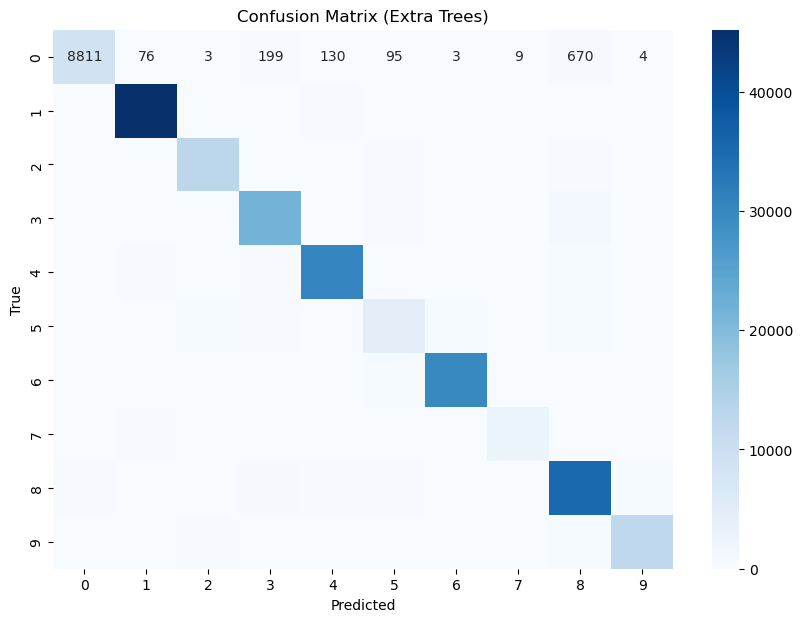


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.9552
  Precision: 0.9559
  Recall:    0.9552
  F1-score:  0.9548

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.87      0.92     10000
           1       0.98      0.99      0.98     45971
           2       0.95      0.97      0.96     13305
           3       0.96      0.92      0.94     23425
           4       0.98      0.95      0.97     32001
           5       0.83      0.71      0.76      6607
           6       0.98      0.99      0.99     30431
           7       0.90      0.88      0.89      3117
           8       0.89      0.98      0.93     37527
           9       0.99      0.95      0.97     12934

    accuracy                           0.96    215318
   macro avg       0.94      0.92      0.93    215318
weighted avg       0.96      0.96      0.95    215318



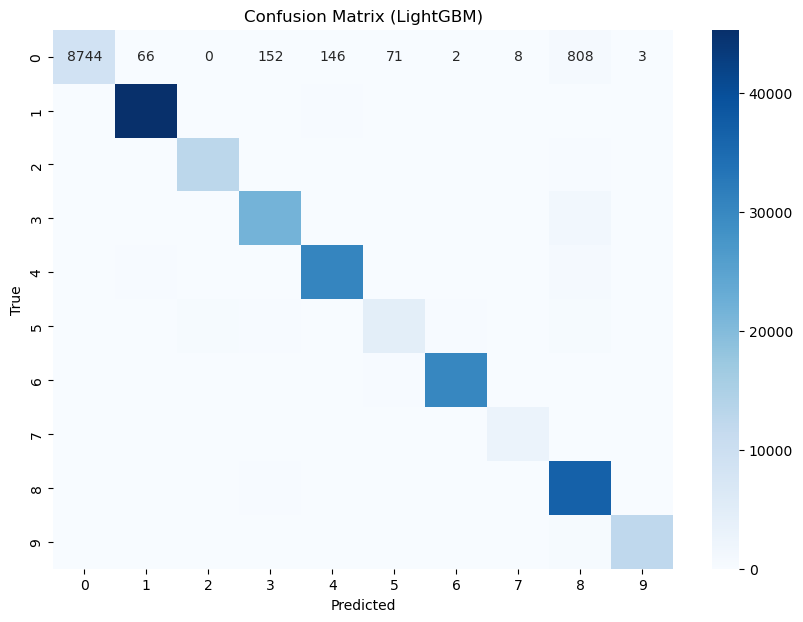


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.9397
  Precision: 0.9405
  Recall:    0.9397
  F1-score:  0.9391

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.85      0.91     10000
           1       0.98      0.98      0.98     45971
           2       0.93      0.96      0.95     13305
           3       0.94      0.90      0.92     23425
           4       0.97      0.95      0.96     32001
           5       0.78      0.63      0.69      6607
           6       0.98      0.99      0.98     30431
           7       0.86      0.83      0.84      3117
           8       0.87      0.96      0.91     37527
           9       0.95      0.93      0.94     12934

    accuracy                           0.94    215318
   macro avg       0.92      0.90      0.91    215318
weighted avg       0.94      0.94      0.94    215318



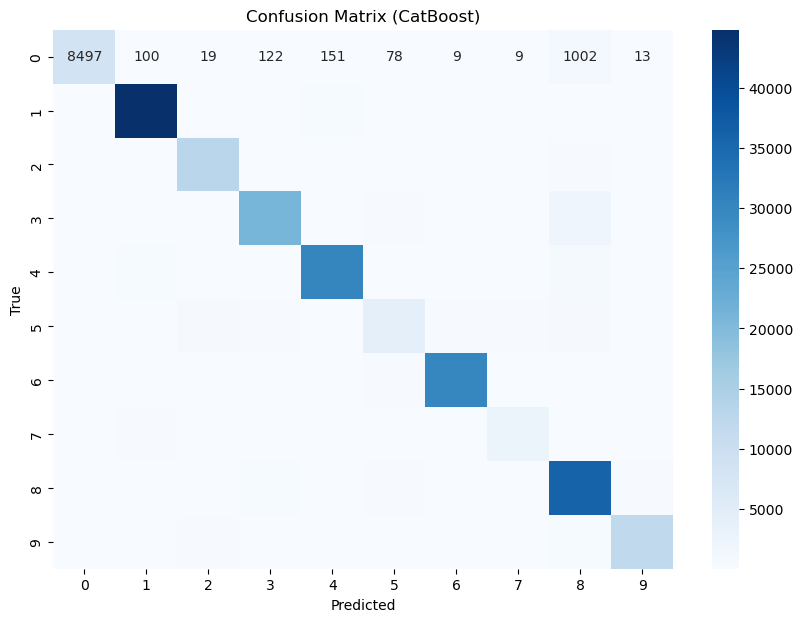


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.842726   0.845179  0.842726  0.841504
Random Forest        0.948917   0.948667  0.948917  0.948592
XGBoost              0.952958   0.953820  0.952958  0.952552
KNN                  0.943001   0.942527  0.943001  0.942462
Naive Bayes          0.540823   0.559218  0.540823  0.530704
Decision Tree        0.904402   0.905530  0.904402  0.903956
Gradient Boosting    0.940214   0.940632  0.940214  0.939547
AdaBoost             0.463612   0.365074  0.463612  0.380647
Extra Trees          0.946382   0.946122  0.946382  0.946122
LightGBM             0.955169   0.955874  0.955169  0.954806
CatBoost             0.939726   0.940454  0.939726  0.939107


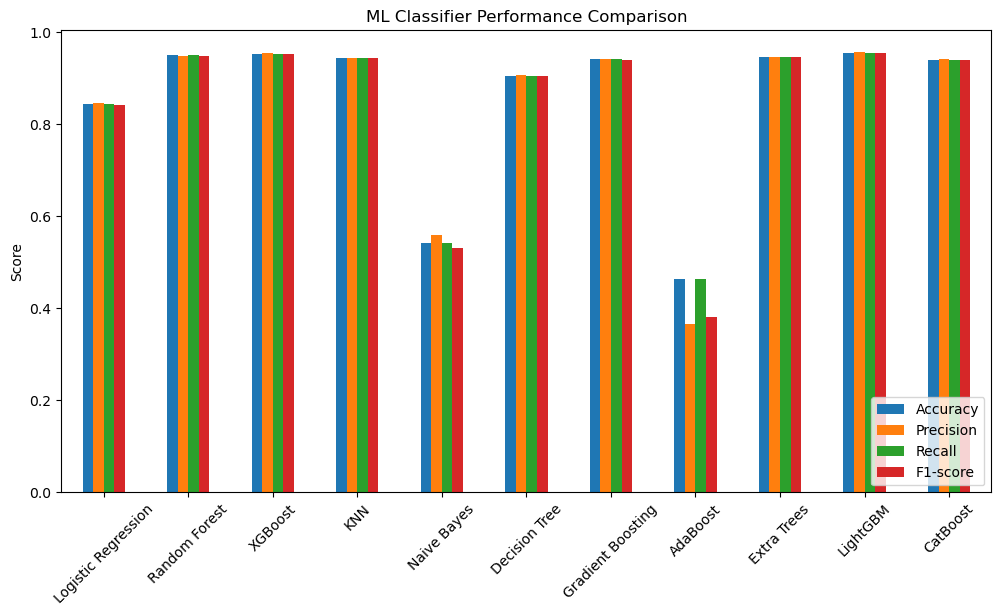

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = encoder.classes_

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"ML-Multi-Attack_type/Multiclass-ml-{name}.pdf")   # <-- save as PDF
    plt.show()


# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack_type/Multi-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\

Logistic Regression Avg Performance:
  Accuracy:  0.8425
  Precision: 0.8452
  Recall:    0.8425
  F1-score:  0.8413

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.9482
  Precision: 0.9479
  Recall:    0.9482
  F1-score:  0.9479

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [07:57:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [07:59:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [08:01:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [08:03:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.9524
  Precision: 0.9532
  Recall:    0.9524
  F1-score:  0.9520

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.9426
  Precision: 0.9421
  Recall:    0.9426
  F1-score:  0.9421

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.5358
  Precision: 0.5549
  Recall:    0.5358
  F1-score:  0.5255

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.9029
  Precision: 0.9044
  Recall:    0.9029
  F1-score:  0.9023

🔹 Training Gradient Boosting with 5-Fold Cross Validation...
Gradient Boosting Avg Performance:
  Accuracy:  0.9396
  Precision: 0.9400
  Recall:    0.9396
  F1-score:  0.9390

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.4700
  Precision: 0.3661
  Recall:    0.4700
  F1-score:  0.3850

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Perf

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.9395
  Precision: 0.9411
  Recall:    0.9395
  F1-score:  0.9393

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.9391
  Precision: 0.9397
  Recall:    0.9391
  F1-score:  0.9384

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.842528   0.845241  0.842528  0.841339
Random Forest        0.948215   0.947922  0.948215  0.947872
XGBoost              0.952404   0.953246  0.952404  0.951957
KNN                  0.942635   0.942092  0.942635  0.942066
Naive Bayes          0.535809   0.554860  0.535809  0.525528
Decision Tree        0.902856   0.904377  0.902856  0.902313
Gradient Boosting    0.939593   0.939998  0.939593  0.938971
AdaBoost             0.469992   0.366108  0.469992  0.385018
Extra Trees          0.945437   0.945116  0.945437  0.945152
LightGBM             0.939453   0.941090  0.939453  0.939309
CatBoost             0.939070 

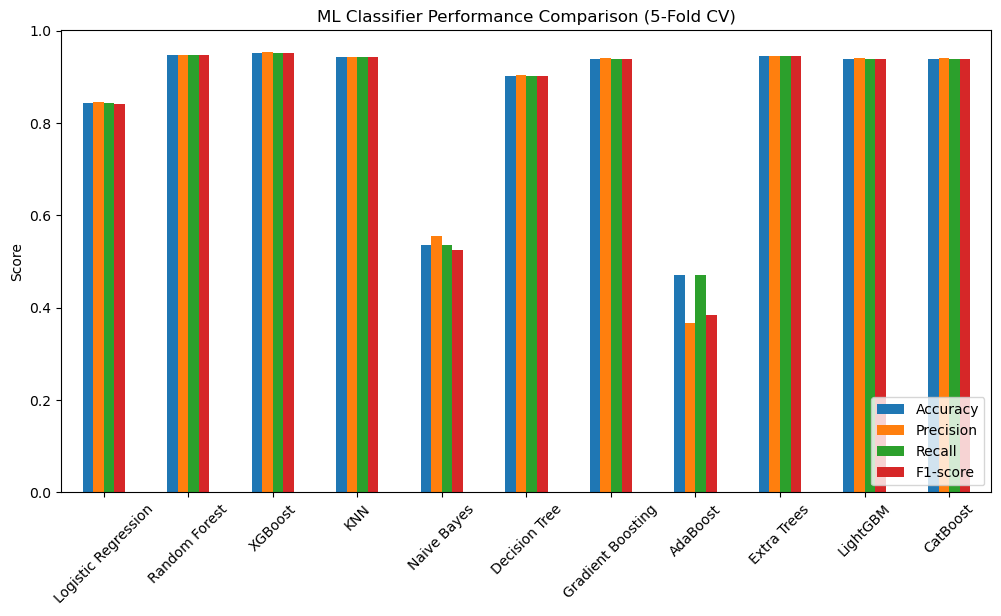

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"ML-Multi-Attack_type/Multi-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack_type/Multi-ml-compare-5fold.pdf")
plt.show()
